# ESS DD cavity pulses

Per-pulse features of the cavity waveforms in the ESS SDS DD captures. The parquet files next to this
notebook are written by `ess_dd_features.py`, which runs on DALIA where the raw data is.

## Where the files come from

The raw data is 43 capture files, `SDS_Data_<window>_DD_<event_id>.tar`. A capture holds 9 to 13 machine cycles.
Inside it there is one parquet per family (SPOKES, MBL, HBL, BCM), with one row per PV and cycle and the
waveform of that PV in the column `data_array` (35,221 samples for a cavity, 80,000 for a beam current monitor).
A cavity has six waveforms per cycle: field, forward power and reflected power, each as amplitude and phase.

The script does this, in order:

1. For each capture, cycle and cavity it takes the six waveforms and turns them into one row: the waveform
   reduced to 64 bin means, and numbers that describe the pulse (level, lengths, flatness, phase, powers).
2. For each capture, cycle and beam current monitor it measures the beam pulse: level, start, length.
3. It reads the interlock log from the Archiver data. A beam trip is the beam permit going to 0: 101 trips.
4. It adds to each cavity row its place in the capture, how far it drifted from the first cycles of that
   capture, the beam of the same cycle and the time to the nearest trip before and after.
5. It computes two correlation tables from the finished cavity table.

## The files

| File | Rows | One row per | Holds |
|---|---|---|---|
| `cavity_pulses.parquet` | 35,414 | capture, cycle and cavity | the features and the binned waveforms of one RF pulse |
| `beam_pulses.parquet` | 5,808 | capture, cycle and BCM device | the beam pulse seen by one monitor |
| `context_correlation.parquet` | 768 | feature, context column and section | Spearman and Pearson r of a pulse feature against beam, trip and cycle context |
| `cavity_comovement.parquet` | 95,670 | feature, lag and pair of cavities | Spearman and Pearson r of one feature between two cavities |
| `mps_transitions.parquet` | 626 | change of an interlock | the machine protection log: interlock, time, value (0 = not ok) |

The first two are data. The two correlation tables are summaries of `cavity_pulses.parquet` and can be recomputed from it.

## Columns of `cavity_pulses.parquet`

| Group | Columns |
|---|---|
| Keys | `event_id` (the capture), `cycle_id` (the machine cycle), `cavity`, `section` |
| Time | `cycle_ts`, `event_ts`, `capture_window`, `seconds_to_event`, `cycle_rank_from_last` (0 = last cycle of the capture) |
| Machine state | `beam_mode`, `beam_state`, `beam_present`, `beam_len`, `beam_current`, `trig_code`, `trig_delay` |
| Bins | `field_amp_bins`, `field_phase_bins`, `fwd_amp_bins`, `refl_amp_bins`: 64 bin means over the whole record |
| Length, in samples | `pulse_len`, `rise_len`, `flat_len`, `fall_len`, `decay_tau` |
| Flatness, relative to the level | `flat_std_rel`, `flat_p2p_rel`, `flat_tilt_rel`, `flat_max_dev_rel`, `flat_max_dev_pos`, `flat_step_max_rel` |
| Phase on the flat top, degrees | `phase_mean_deg`, `phase_std_deg`, `phase_p2p_deg`, `phase_tilt_deg` |
| Power | `fwd_peak`, `fwd_flat`, `fwd_flat_std_rel`, `refl_flat`, `refl_fill_peak`, `refl_end_peak`, `refl_ratio` |
| Drift within the capture | `<feature>_drift`, `shape_drift`, `field_end_after_rf_off` |
| Beam and trips | `beam_level`, `beam_start_us`, `beam_len_us`, `beam_after_flat_start_us`, `seconds_to_next_trip`, `seconds_since_last_trip` |

`has_pulse` is false for the 427 cycles in which the cavity had no RF pulse; their feature columns are empty.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

# Sections in the order the beam crosses them.
LINAC = ["Spk", "MBL", "HBL"]
# Blue for negative r, red for positive, grey at zero.
INK, MUTED, SURFACE = "#1a1a19", "#6b6b66", "#fcfcfb"
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", ["#184f95", "#f0efec", "#a8322a"])
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "text.color": INK, "axes.labelcolor": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": SURFACE, "font.size": 9})

# The files sit next to the notebook, so they are read by name.
pulses = pd.read_parquet("cavity_pulses.parquet")
beam = pd.read_parquet("beam_pulses.parquet")
context = pd.read_parquet("context_correlation.parquet")
comovement = pd.read_parquet("cavity_comovement.parquet")
print(f"{len(pulses):,} pulses, {pulses.cavity.nunique()} cavities, {pulses.event_id.nunique()} captures, "
      f"{pulses.cycle_ts.min():%Y-%m-%d} to {pulses.cycle_ts.max():%Y-%m-%d}")
# Median of a few features per section: what a normal pulse looks like there.
pulses.groupby("section")[["pulse_len", "flat_len", "flat_std_rel", "flat_tilt_rel", "phase_std_deg", "decay_tau", "refl_ratio"]].median()

35,414 pulses, 81 cavities, 43 captures, 2025-05-29 to 2026-06-30


,pulse_len,flat_len,flat_std_rel,flat_tilt_rel,phase_std_deg,decay_tau,refl_ratio
section,,,,,,,
HBL,17559.0,14742.0,0.000103,0.000023,0.018294,2399.091189,0.950177
MBL,17778.0,14759.0,0.000180,0.000089,0.020238,2733.842023,0.944047
Spk,17136.0,14750.0,0.000419,-0.000498,0.065074,1659.930277,0.969660


In [2]:
# One row of each table.
for name, table in [("cavity_pulses", pulses), ("beam_pulses", beam), ("context_correlation", context), ("cavity_comovement", comovement)]:
    print(f"\n{name}: {len(table):,} rows, {table.shape[1]} columns")
    print(table.drop(columns=[c for c in table if c.endswith("_bins")]).iloc[0].to_string())


cavity_pulses: 35,414 rows, 69 columns
event_id                                            15643300300
cycle_id                                            15643300178
capture_window                      20250528_2045_20250530_0416
cycle_ts                    2025-05-29 12:28:19.832928256+00:00
event_ts                    2025-05-29 12:28:28.575492352+00:00
trig_code                                                    15
trig_delay                                           200.005676
beam_mode                                                 Probe
beam_state                                     BEAM_PRESENT_YES
beam_present                                               True
beam_len                                                      5
beam_current                                               5227
cavity                                   HBL-010RFC:RFS-DIG-101
section                                                     HBL
array_size                                                35221


## Feature against context

Correlation between a feature, taken as its deviation within the cavity, and a context column.
Spearman works on ranks, Pearson on the values: a few extreme pulses can set Pearson and barely move Spearman.
Beam current and the trip timings are constant within a capture, so those columns compare the 43 captures with each other.

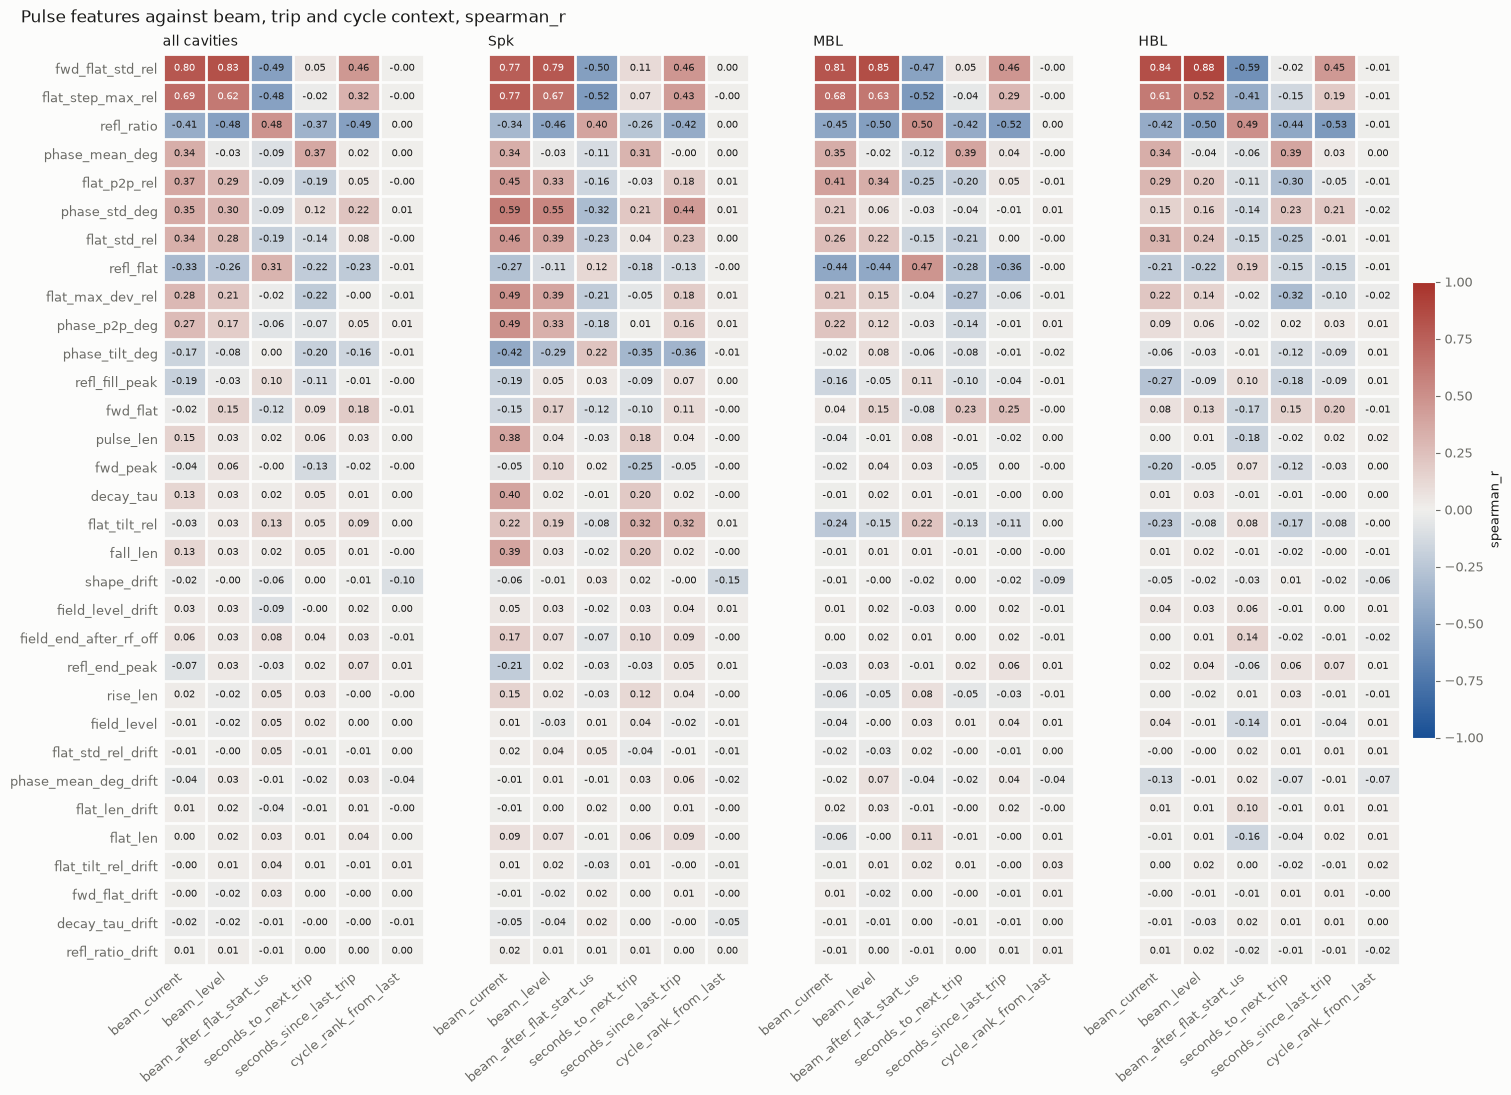

In [3]:
def plot_context(method):
    # One panel for all cavities and one per section. Rows are sorted by the strongest r in the first panel.
    sections = ["all"] + LINAC
    features = context[context.section == "all"].groupby("feature")[method].apply(lambda r: r.abs().max()).sort_values(ascending=False).index
    columns = list(dict.fromkeys(context.context))
    fig, axes = plt.subplots(1, len(sections), figsize=(15, 0.27 * len(features) + 2.2), sharey=True, constrained_layout=True)
    for ax, section in zip(axes, sections):
        # The table is long (one row per feature and context column); pivot turns it into a feature by context grid.
        grid = context[context.section == section].pivot(index="feature", columns="context", values=method).reindex(index=features, columns=columns)
        image = ax.imshow(grid.to_numpy(), cmap=DIVERGING, vmin=-1, vmax=1, aspect="auto")
        for (i, j), r in np.ndenumerate(grid.to_numpy()):
            if not np.isnan(r):
                ax.text(j, i, f"{r:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(r) > 0.6 else INK)
        ax.set_xticks(range(len(columns)), columns, rotation=40, ha="right")
        ax.set_yticks(range(len(features)), features)
        ax.set_xticks(np.arange(-0.5, len(columns)), minor=True)
        ax.set_yticks(np.arange(-0.5, len(features)), minor=True)
        ax.grid(which="minor", color=SURFACE, linewidth=2)
        ax.tick_params(which="both", length=0)
        ax.set_title("all cavities" if section == "all" else section, loc="left", fontsize=10)
    fig.colorbar(image, ax=axes, shrink=0.5, pad=0.01, label=method)
    fig.suptitle(f"Pulse features against beam, trip and cycle context, {method}", x=0.01, ha="left", fontsize=12)
    plt.show()


plot_context("spearman_r")

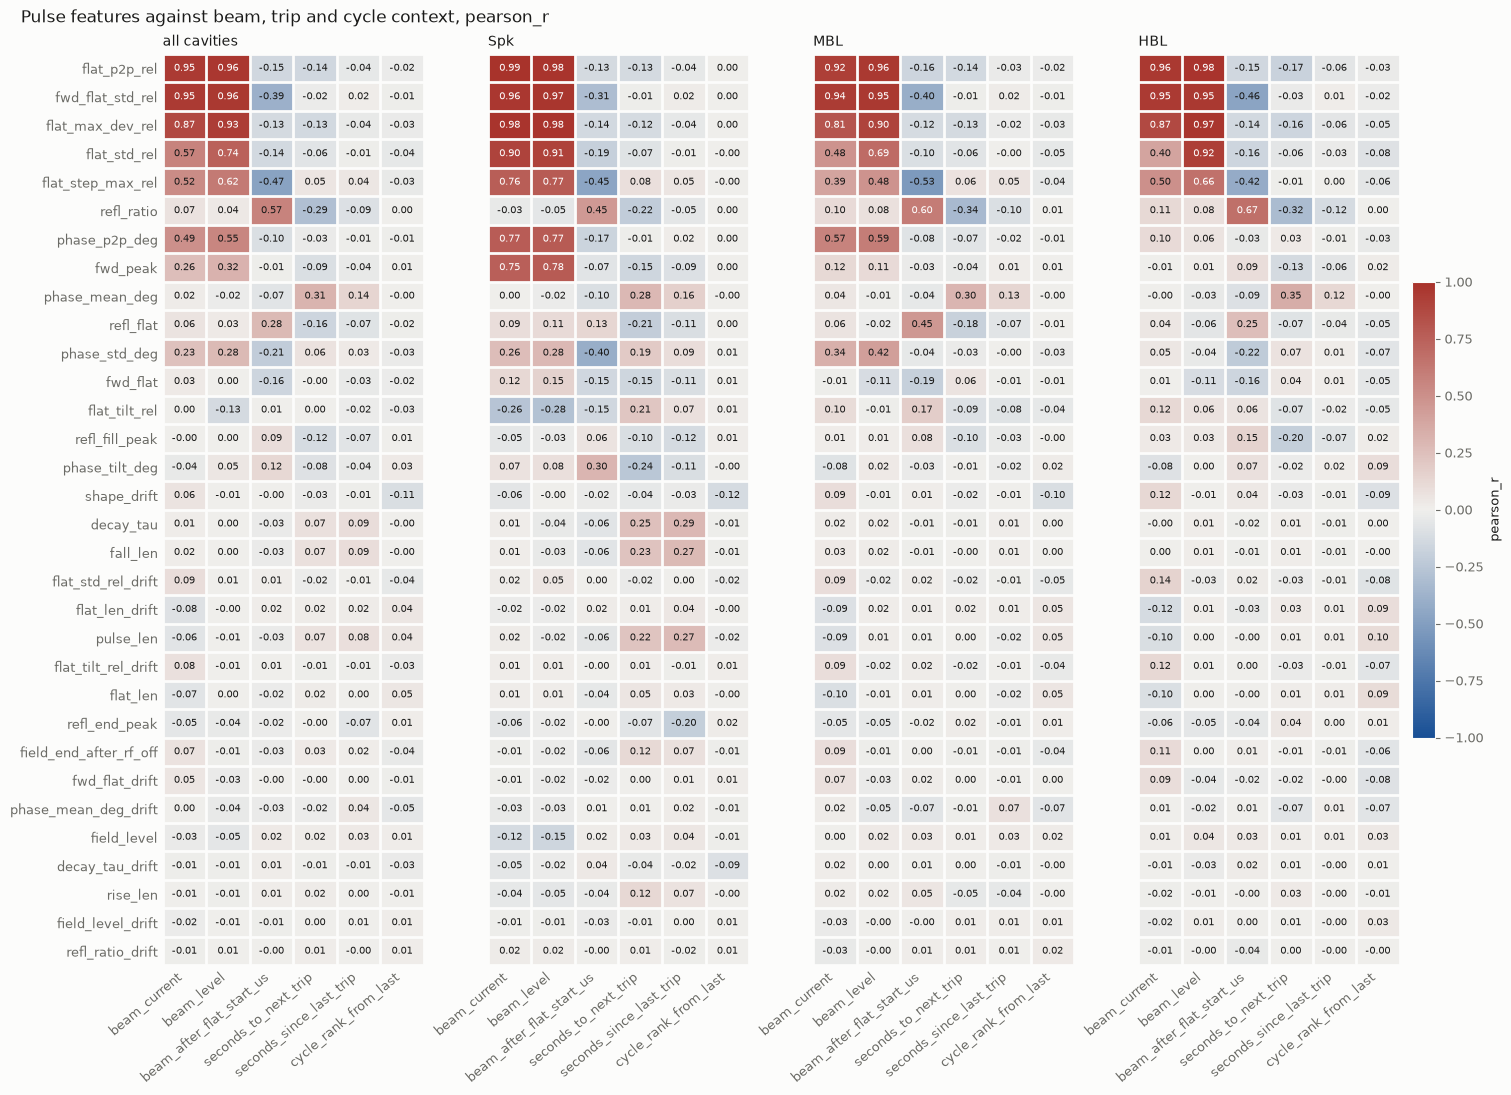

In [4]:
plot_context("pearson_r")

## Cavity against cavity

Correlation of one feature between two cavities, as deviations from the mean of the capture.
Lag 1 pairs a cavity with the other cavity one captured cycle later. Cavities run along the linac.
The Pearson block over MBL and HBL at lag 0 comes from the trip pulses listed further down.

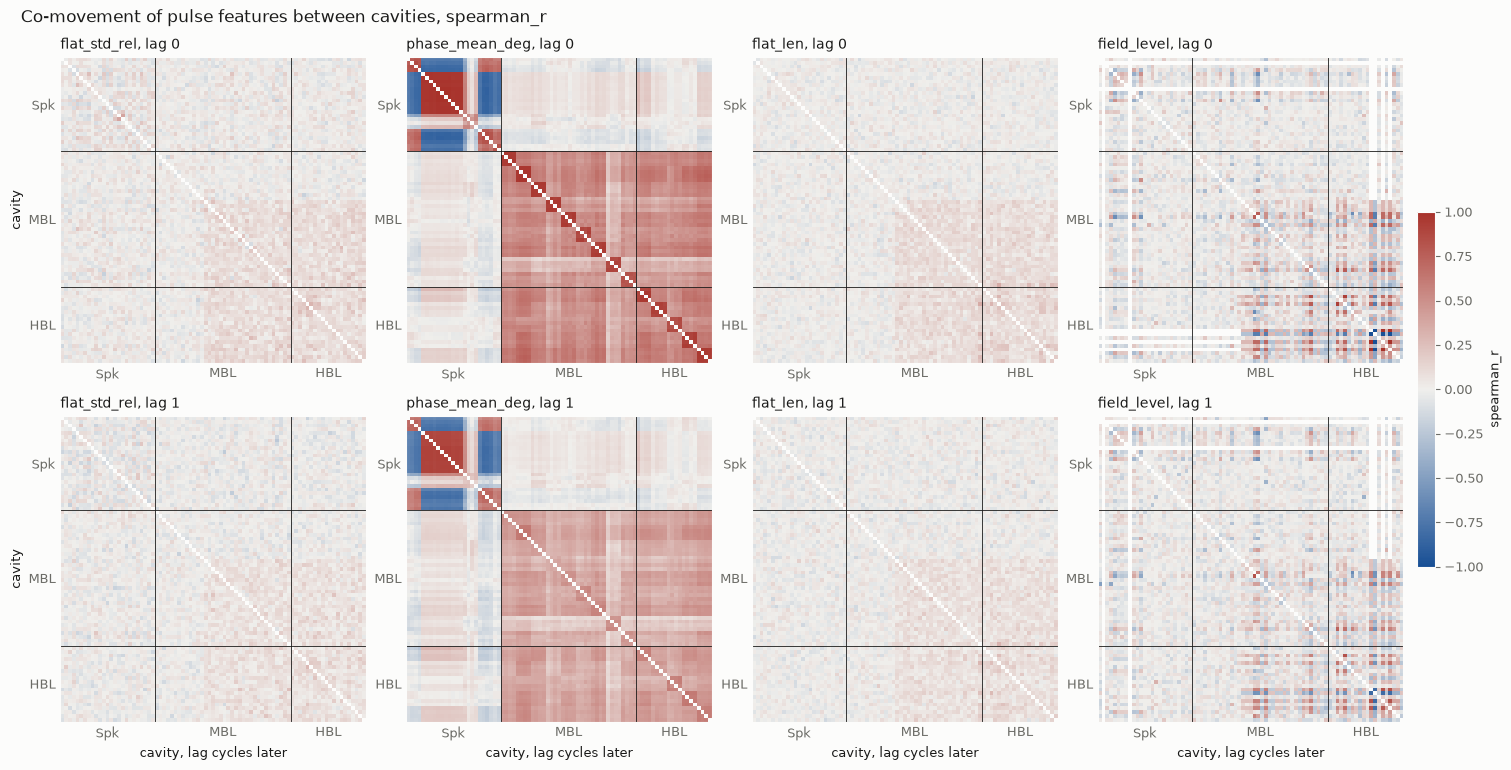

In [5]:
def plot_comovement(method):
    # Cavities in linac order, and the index at which each section starts, for the dividing lines.
    order = pulses.drop_duplicates("cavity").assign(rank=lambda d: d.section.map(LINAC.index)).sort_values(["rank", "cavity"])
    sizes = order.groupby("section", sort=False).size()
    cavities, starts = order.cavity.to_list(), sizes.cumsum().shift(fill_value=0)
    shown = ["flat_std_rel", "phase_mean_deg", "flat_len", "field_level"]
    fig, axes = plt.subplots(2, len(shown), figsize=(15, 7.6), constrained_layout=True)
    for column, feature in enumerate(shown):
        for row, lag in enumerate((0, 1)):
            ax = axes[row, column]
            # Row: a cavity. Column: the other cavity, lag captured cycles later.
            pairs = comovement[(comovement.feature == feature) & (comovement.lag_cycles == lag)]
            grid = pairs.pivot(index="cavity", columns="cavity_later", values=method).reindex(index=cavities, columns=cavities)
            image = ax.imshow(grid.to_numpy(), cmap=DIVERGING, vmin=-1, vmax=1)
            for start in starts.iloc[1:]:
                ax.axhline(start - 0.5, color=INK, linewidth=0.6)
                ax.axvline(start - 0.5, color=INK, linewidth=0.6)
            middles = [start + size / 2 - 0.5 for start, size in zip(starts, sizes)]
            ax.set_xticks(middles, starts.index)
            ax.set_yticks(middles, starts.index)
            ax.tick_params(length=0)
            ax.set_title(f"{feature}, lag {lag}", loc="left", fontsize=10)
            if column == 0:
                ax.set_ylabel("cavity")
            if row == 1:
                ax.set_xlabel("cavity, lag cycles later")
    fig.colorbar(image, ax=axes, shrink=0.5, pad=0.01, label=method)
    fig.suptitle(f"Co-movement of pulse features between cavities, {method}", x=0.01, ha="left", fontsize=12)
    plt.show()


plot_comovement("spearman_r")

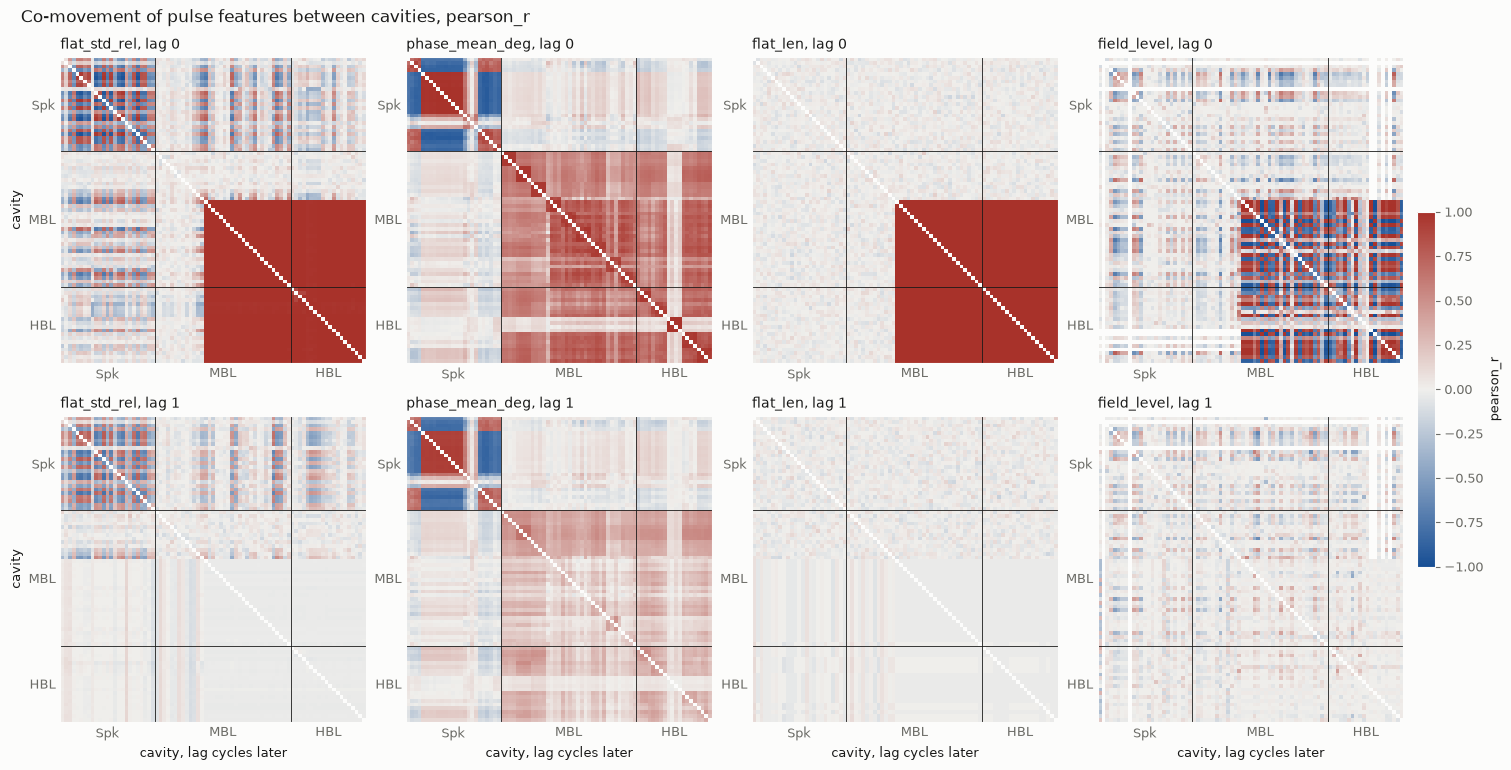

In [6]:
plot_comovement("pearson_r")

## Cycles with a cut flat top

Cycles in which several cavities have a flat top more than 10 % shorter than their own median.

In [7]:
# A pulse is cut when its flat top is more than 10 % shorter than the median flat top of the same cavity.
live = pulses[pulses.has_pulse]
cut = live[live.flat_len < 0.9 * live.groupby("cavity").flat_len.transform("median")]
(cut.groupby(["event_id", "cycle_id"])
    .agg(cycle_ts=("cycle_ts", "first"), cavities=("cavity", "size"), sections=("section", lambda s: " ".join(sorted(set(s)))),
         flat_len=("flat_len", "median"), seconds_to_next_trip=("seconds_to_next_trip", "first"), beam_state=("beam_state", "first"))
    .sort_values("cavities", ascending=False).head(10))

cycle_ts  cavities  \
event_id    cycle_id                                                    
16122602164 16122596526 2026-06-29 18:13:56.056804520+00:00        43   
16122702964 16122697297 2026-06-29 20:13:54.056474319+00:00         9   
16098811907 16098811906 2026-06-10 02:19:45.699300712+00:00         4   
16098813939 16098813852 2026-06-10 02:22:04.699294341+00:00         4   
            16098813838 2026-06-10 02:22:03.699294386+00:00         4   
            16098813824 2026-06-10 02:22:02.699294432+00:00         4   
            16098813810 2026-06-10 02:22:01.699294477+00:00         4   
            16098813796 2026-06-10 02:22:00.699294523+00:00         4   
            16098813782 2026-06-10 02:21:59.699294568+00:00         4   
            16098813768 2026-06-10 02:21:58.699294614+00:00         4   

                        sections  flat_len  seconds_to_next_trip  \
event_id    cycle_id                                               
16122602164 16122596526  HBL MBL    1855.0              0.632005   
16122702964 16122697297  HBL MBL    1814.0              0.610176   
16098811907 16098811906      MBL    6375.5          12347.960598   
16098813939 16098813852      MBL    6375.5          12208.960604   
            16098813838      MBL    6377.0          12209.960604   
            16098813824      MBL    6376.0          12210.960604   
            16098813810      MBL    6376.5          12211.960604   
            16098813796      MBL    6374.5          12212.960604   
            16098813782      MBL    6375.5          12213.960604   
            16098813768      MBL    6375.0          12214.960604   

                                    beam_state  
event_id    cycle_id                            
16122602164 16122596526       BEAM_PRESENT_YES  
16122702964 16122697297  BEAM_PRESENT_YES_FAKE  
16098811907 16098811906           BEAM_INHIBIT  
16098813939 16098813852           BEAM_INHIBIT  
            16098813838           BEAM_INHIBIT  
            16098813824           BEAM_INHIBIT  
            16098813810           BEAM_INHIBIT  
            16098813796           BEAM_INHIBIT  
            16098813782           BEAM_INHIBIT  
            16098813768           BEAM_INHIBIT

## Binned waveforms

`field_amp_bins`, `field_phase_bins`, `fwd_amp_bins` and `refl_amp_bins` hold each record as 64 bin means.

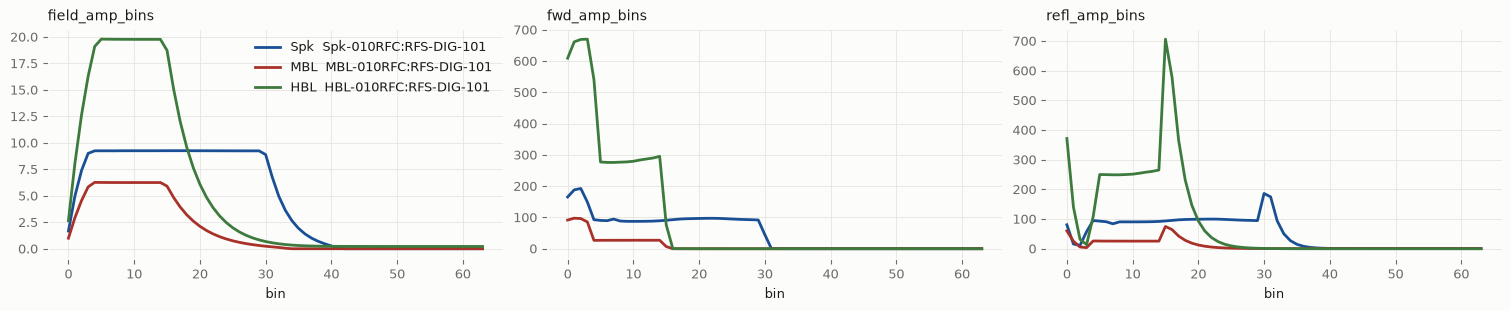

In [8]:
# The first pulse of one cavity per section.
one = pulses[pulses.has_pulse].groupby("section").head(1).set_index("section").loc[LINAC]
fig, axes = plt.subplots(1, 3, figsize=(15, 3), constrained_layout=True)
for ax, name in zip(axes, ["field_amp_bins", "fwd_amp_bins", "refl_amp_bins"]):
    for section, color in zip(LINAC, ["#184f95", "#a8322a", "#3d7a3d"]):
        ax.plot(one.loc[section, name], color=color, linewidth=2, label=f"{section}  {one.loc[section, 'cavity']}")
    ax.set_title(name, loc="left", fontsize=10)
    ax.set_xlabel("bin")
    ax.grid(color="#e6e5e0", linewidth=0.6)
axes[0].legend(frameon=False)
plt.show()

## How the code works

`ess_dd_features.py` sits next to this notebook. The cells below show its functions in the order they run,
each after a short explanation. The code shown is read from that file.

In [9]:
import ast
from IPython.display import Code

SCRIPT = open("ess_dd_features.py").read()
FUNCTIONS = {node.name: ast.get_source_segment(SCRIPT, node) for node in ast.parse(SCRIPT).body if isinstance(node, ast.FunctionDef)}


def show(name):
    return Code(FUNCTIONS[name], language="python")

### 1. Order of the steps: `main`

`main` is the whole run. It lists the capture files, hands one file to each worker process, collects the rows
they return, reads the beam trips, adds the context columns, computes the two correlation tables and writes the
parquet files. `python ess_dd_features.py <raw> <out> <DD|PM> <n_bins> [<max_events>]`: `DD` is used here,
`n_bins` is 64, `max_events` keeps only some captures for a quick trial.

In [10]:
show("main")

def main() -> None:
    if len(sys.argv) not in (5, 6) or sys.argv[3] not in CAPTURE_TYPES:
        raise SystemExit(__doc__)
    raw, out, capture_type, n_bins = Path(sys.argv[1]), Path(sys.argv[2]), sys.argv[3], int(sys.argv[4])
    tars = sorted(raw.glob(f"SDS_Data_*_{capture_type}_*.tar"))
    if len(sys.argv) == 6:
        keep = np.unique(np.linspace(0, len(tars) - 1, int(sys.argv[5])).round().astype(int))
        tars = [tars[i] for i in keep]
    out.mkdir(parents=True, exist_ok=True)
    workers = len(os.sched_getaffinity(0))
    print(f"{len(tars)} {capture_type} captures, {workers} workers", flush=True)

    # 1. One worker per capture reads its parquet files and returns the feature rows.
    cavity_rows, beam_rows = [], []
    with Pool(workers) as pool:
        for done, (cav, beam) in enumerate(pool.imap_unordered(process_tar, [(str(t), n_bins) for t in tars]), 1):
            cavity_rows += cav
            beam_rows += beam
            print(f"{done}/{len(tars)} captures, {len(cavity_rows)} cavity pulses, {len(beam_rows)} beam pulses", flush=True)
    # 2. Interlock changes from the Archiver. A beam trip is the beam permit going to 0.
    mps = load_mps(raw)
    trips = pd.DatetimeIndex(mps.data_ts[(mps.pv == PERMIT) & (mps.value == 0)])
    print(f"{len(mps)} interlock changes on {mps.pv.nunique()} interlocks, {len(trips)} beam trips", flush=True)

    # 3. The cavity table gets its drift columns, the beam of the cycle and the trip timings.
    beam = pd.DataFrame(beam_rows)
    df = add_beam_and_trips(add_cycle_context(pd.DataFrame(cavity_rows)), beam, trips)
    # 4. The two correlation tables are computed from the finished cavity table.
    context, comovement = context_correlation(df), cavity_comovement(df)
    # 5. cavity_pulses and beam_pulses are the data; the two correlation tables are summaries of cavity_pulses.
    df.to_parquet(out / "cavity_pulses.parquet", index=False)
    beam.to_parquet(out / "beam_pulses.parquet", index=False)
    context.to_parquet(out / "context_correlation.parquet", index=False)
    comovement.to_parquet(out / "cavity_comovement.parquet", index=False)
    mps.to_parquet(out / "mps_transitions.parquet", index=False)

    pd.set_option("display.width", 200)
    print(f"\ncavity_pulses: {len(df)} rows, {df.cavity.nunique()} cavities, {df.event_id.nunique()} captures, "
          f"{int((~df.has_pulse).sum())} without pulse")
    print(df.groupby("section")[["pulse_len", "flat_len", "flat_std_rel", "flat_tilt_rel", "phase_std_deg", "decay_tau", "refl_ratio"]]
          .median().round(5).to_string())
    print(f"\nbeam_pulses: {len(beam)} rows, {int(beam.has_beam.sum()) if len(beam) else 0} with beam")
    print("\nstrongest feature against context (section all):")
    print(context[context.section == "all"].sort_values("spearman_r", key=np.abs, ascending=False).head(20).to_string(index=False))
    print("\nmean r between cavities:")
    print(comovement.groupby(["feature", "lag_cycles", "same_section"])[["spearman_r", "pearson_r"]].mean().round(3).to_string())

### 2. Reading one capture: `process_tar` and `parquet_rows`

A capture is a tar holding one parquet per family. `process_tar` reads each parquet straight out of the tar and
hands it to `parquet_rows`, which builds the rows. Every row of the parquet is one
PV in one cycle, and `data_array` is its waveform. The PV name says what the waveform is: `CAVITY_PV` picks the
cavity, the signal (`Dwn0` field, `Dwn5` forward, `Dwn6` reflected) and the component (`Cmp0` amplitude, `Cmp1`
phase); `BCM_PV` picks a beam current monitor. The six waveforms of a cavity in a cycle are grouped and passed
to `pulse_features`; each monitor waveform is passed to `beam_features`. What comes back is a list of rows.

In [11]:
show("process_tar")

def process_tar(job: tuple[str, int]) -> tuple[list[dict], list[dict]]:
    """Rows of one capture. Its tar holds SDS_Data/<window>/<DD|PM>/<event_id>/<family>.parquet, with family one of
    SPOKES, MBL, HBL, BCM, BPM."""
    path, n_bins = job
    cavity_rows, beam_rows = [], []
    with tarfile.open(path) as tar:
        for member in tar.getmembers():
            if not member.name.endswith(".parquet"):
                continue
            # The tar is not compressed, so the parquet is read in place, without extracting it to disk.
            cavity, beam = parquet_rows(tar.extractfile(member), member.name.split("/")[1], n_bins)
            cavity_rows += cavity
            beam_rows += beam
    return cavity_rows, beam_rows

In [12]:
show("parquet_rows")

def parquet_rows(source, capture_window: str, n_bins: int) -> tuple[list[dict], list[dict]]:
    """Rows of one DD parquet: one per cavity and cycle, one per BCM device and cycle.

    The parquet has one row per pv and cycle; the waveform of that pv in that cycle is the list data_array.
    source is a path or an open file.
    """
    cavity_rows, beam_rows = [], []
    pf = pq.ParquetFile(source)
    # The names are read first: a file with no cavity or beam current waveform (the BPM files) is left unread.
    names = pf.read(columns=["pv"]).column("pv").to_pandas()
    if names.str.extract(CAVITY_PV).cavity.isna().all() and names.str.extract(BCM_PV).device.isna().all():
        return cavity_rows, beam_rows
    table = pf.read(columns=META + ["data_array"])
    meta = table.select(META).to_pandas()
    # data_array is stored as one long array of samples plus the offset at which each row starts. Slicing
    # that array gives the waveform of a row without turning thirty thousand samples into Python objects.
    arrays = table.column("data_array").combine_chunks()
    offsets, values = arrays.offsets.to_numpy(), arrays.values.to_numpy()
    wave = lambda i: values[offsets[i]:offsets[i + 1]]
    meta["start_us"] = (meta.data_ts - meta.cycle_ts).dt.total_seconds() * 1e6
    # Columns that describe the cycle and the capture, the same on every row built from it.
    common = lambda r: {
        "event_id": int(r.event_id), "cycle_id": int(r.cycle_id), "capture_window": capture_window,
        "cycle_ts": r.cycle_ts, "event_ts": r.event_ts, "trig_code": int(r.trig_code), "trig_delay": float(r.trig_delay),
        "beam_mode": r.beam_mode, "beam_state": r.beam_state, "beam_present": bool(r.beam_present),
        "beam_len": int(r.beam_len), "beam_current": int(r.beam_current)}

    # Cavity rows: the pv name gives the cavity, the signal and the component. The six waveforms of one
    # cavity in one cycle are gathered under field_amp, field_phase, fwd_amp, fwd_phase, refl_amp, refl_phase
    # and turned into one row of features. Records shorter than n_bins are empty or cut and are left out.
    cav = meta.join(meta.pv.str.extract(CAVITY_PV)).dropna(subset="cavity")
    for (_, cavity), g in cav.groupby(["cycle_id", "cavity"]):
        sig = {f"{SIGNAL[d]}_{COMPONENT[c]}": wave(i) for i, d, c in zip(g.index, g.dwn, g.cmp) if len(wave(i)) >= n_bins}
        if "field_amp" not in sig:
            continue
        r = g.iloc[0]
        cavity_rows.append({**common(r), "cavity": cavity, "section": r.section, **pulse_features(sig, n_bins, r.start_us)})

    # Beam rows: one waveform per beam current monitor and cycle.
    bcm = meta.join(meta.pv.str.extract(BCM_PV)).dropna(subset="device")
    for i, r in bcm.iterrows():
        if len(wave(i)):
            beam_rows.append({**common(r), "device": r.device, **beam_features(wave(i), r.start_us)})
    return cavity_rows, beam_rows

### 3. Six waveforms become one row: `pulse_features`

The field amplitude drives everything.

1. **Baseline and level.** The baseline is the median of the end of the record, after the pulse. The level is
   the median of the samples near the top, above the baseline. If the level does not stand clear of the baseline
   noise, the cycle has no pulse: only the bins are kept.
2. **Bins.** Each waveform is cut in 64 stretches and each stretch is replaced by its mean.
3. **Lengths.** The field is rescaled so that the baseline is 0 and the level is 1. A length is the number of
   samples between two crossings: above 50 % for `pulse_len`, 10 to 90 % for `rise_len`, above 98 % for
   `flat_len`, 90 to 10 % for `fall_len`. `decay_tau` is the time constant of the exponential fall.
4. **Flatness.** Inside the flat top, 5 % trimmed at each end: spread, peak to peak, tilt from start to end,
   largest deviation and where it sits, largest jump between neighbouring blocks.
5. **Phase.** Mean, spread, peak to peak and tilt of the phase over the same window, computed on the unit circle
   so that a phase near 180 degrees does not break the mean.
6. **Power.** Forward: peak during filling and value on the flat top. Reflected: value on the flat top, peak
   during filling, peak when the RF goes off. `refl_ratio` is reflected over forward on the flat top.
7. **RF off.** `field_end_after_rf_off` is the end of the flat top minus the sample where the forward power goes
   off. A negative value means the field left the flat top while the RF was still on.

In [13]:
show("pulse_features")

def pulse_features(sig: dict[str, np.ndarray], n_bins: int, start_us: float) -> dict:
    """Features of one cavity in one cycle. sig: field_amp, and what exists of field_phase, fwd_amp, refl_amp."""
    a = sig["field_amp"].astype(np.float64)
    n = len(a)
    # Baseline: the end of the record, long after the pulse. Level: the median of the samples near the top, taken
    # above the baseline. A record counts as a pulse when the level stands clear of the noise of the baseline.
    tail = a[-(n // TAIL):]
    base = float(np.median(tail))
    level = float(np.median(a[a >= base + 0.9 * (np.percentile(a, 99) - base)])) - base
    out = {"array_size": n, "field_base": base, "field_level": level, "has_pulse": bool(level > 5 * tail.std() and level > 0)}
    # Bins are kept for every record, pulse or not: a missing pulse is itself worth seeing.
    for name in ("field_amp", "fwd_amp", "refl_amp"):
        if name in sig:
            out[f"{name}_bins"] = bin_means(sig[name].astype(np.float64), n_bins).astype(np.float32)
    if "field_phase" in sig:
        out["field_phase_bins"] = np.rad2deg(np.angle(bin_means(unit(sig["field_phase"]), n_bins))).astype(np.float32)
    if not out["has_pulse"]:
        return out

    # rel is the field as a share of its level: 0 on the baseline, 1 on the flat top. Each length is the distance
    # between two crossings of a share: 10, 20, 50, 90 or 98 %.
    rel = (a - base) / level
    half_start, half_end = first_last(rel > 0.5)
    rise10, fall10 = first_last(rel > 0.1)
    rise90, fall90 = first_last(rel > 0.9)
    flat_start, flat_end = first_last(rel > FLAT)
    _, fall20 = first_last(rel > 0.2)
    # After the RF goes off the field falls as exp(-t / tau): the log of the fall is a line of slope -1 / tau.
    decay = slope(np.log(np.clip(rel[flat_end:fall20 + 1], 1e-6, None))) if fall20 - flat_end >= 8 else np.nan
    # start_us is the time of the first sample after cycle_ts, so start_us + index * dt places a crossing in the cycle.
    dt = RF_DT_US if n == RF_SAMPLES else np.nan
    out.update(pulse_len=half_end - half_start, rise_len=rise90 - rise10, flat_len=flat_end - flat_start,
               fall_len=fall10 - fall90, decay_tau=-1 / decay if decay < 0 else np.nan,
               pulse_start_us=start_us + half_start * dt, flat_start_us=start_us + flat_start * dt,
               flat_end_us=start_us + flat_end * dt)

    # Flatness is measured inside the flat top, with 5 % cut at each end to stay clear of the two corners.
    trim = (flat_end - flat_start) // 20
    top = slice(flat_start + trim, flat_end - trim + 1)
    w = rel[top]
    if len(w) < FLAT_BLOCKS:
        return out
    dev = np.abs(w - np.median(w))
    # A step shows as a jump between the means of two neighbouring blocks, which sample noise does not produce.
    blocks = w[:len(w) // FLAT_BLOCKS * FLAT_BLOCKS].reshape(FLAT_BLOCKS, -1).mean(axis=1)
    out.update(flat_std_rel=float(w.std()), flat_p2p_rel=float(w.max() - w.min()), flat_tilt_rel=slope(w) * len(w),
               flat_max_dev_rel=float(dev.max()), flat_max_dev_pos=float(dev.argmax() / len(w)),
               flat_step_max_rel=float(np.abs(np.diff(blocks)).max()))

    # Phase, forward and reflected power are read over the same flat-top window as the field, so they are used only
    # when their record has the length of the field record.
    if len(sig.get("field_phase", ())) == n:
        z = unit(sig["field_phase"][top])
        mean = z.mean()
        d = np.rad2deg(np.angle(z * np.conj(mean)))
        out.update(phase_mean_deg=float(np.rad2deg(np.angle(mean))), phase_std_deg=float(d.std()),
                   phase_p2p_deg=float(d.max() - d.min()), phase_tilt_deg=slope(d) * len(d))
    fwd_flat = np.nan
    if len(sig.get("fwd_amp", ())) == n:
        f = sig["fwd_amp"].astype(np.float64)
        f -= np.median(f[-(n // TAIL):])
        fwd_flat = float(np.median(f[top]))
        out.update(fwd_peak=float(f.max()), fwd_peak_idx=int(f.argmax()), fwd_flat=fw

The four small helpers it uses:

In [14]:
Code("\n\n\n".join(FUNCTIONS[name] for name in ("first_last", "slope", "bin_means", "unit")), language="python")

def first_last(mask: np.ndarray) -> tuple[int, int]:
    """First and last sample at which the mask holds."""
    idx = np.flatnonzero(mask)
    return int(idx[0]), int(idx[-1])


def slope(y: np.ndarray) -> float:
    """Least-squares slope of y per sample."""
    x = np.arange(len(y)) - (len(y) - 1) / 2
    return float(x @ (y - y.mean()) / (x @ x))


def bin_means(x: np.ndarray, n_bins: int) -> np.ndarray:
    """Mean of x over n_bins consecutive stretches that cover the whole record."""
    edges = np.linspace(0, len(x), n_bins + 1).astype(int)
    return np.add.reduceat(x, edges[:-1]) / np.diff(edges)


def unit(phase_deg: np.ndarray) -> np.ndarray:
    """Phase as a point on the unit circle, so that means and differences survive the jump from 180 to -180 degrees."""
    return np.exp(1j * np.deg2rad(phase_deg))

### 4. The beam pulse: `beam_features`

The beam is short against the record, so the median of the record is the baseline. Some monitors read the beam
as a negative pulse and are flipped. A waveform has beam when its peak is 8 times above the noise. The level is
the median of the samples above half of the peak; start and length come from the crossings of half of the level.

In [15]:
show("beam_features")

def beam_features(a: np.ndarray, start_us: float) -> dict:
    """Features of one BCM waveform. The beam pulse is short against the record, so the median is the baseline."""
    d = a.astype(np.float64) - np.median(a)
    # Some devices read the beam as a negative pulse; it is flipped so that the beam always points up.
    polarity = -1 if -d.min() > d.max() else 1
    d *= polarity
    peak = float(d.max())
    # Noise as 1.4826 times the median absolute deviation, which the beam pulse itself does not inflate.
    noise = 1.4826 * np.median(np.abs(d)) or d.std()
    out = {"array_size": len(a), "beam_polarity": polarity, "beam_peak": peak, "has_beam": bool(peak > 8 * noise)}
    if not out["has_beam"]:
        return out
    level = float(np.median(d[d > 0.5 * peak]))
    start, end = first_last(d > 0.5 * level)
    # The beam pulse with a tenth cut at each end, for its flatness.
    core = d[start + (end - start) // 10:end - (end - start) // 10 + 1]
    out.update(beam_level=level, beam_start_us=start_us + start * BCM_DT_US, beam_len_us=(end - start) * BCM_DT_US,
               beam_flat_std_rel=float(core.std() / level), beam_charge=float(d[start:end + 1].sum() * BCM_DT_US))
    return out

### 5. The interlock log and the beam trips: `load_mps`

The Archiver tar holds slow scalar data. Its MPS files log the machine protection interlocks, one row each time
an interlock changes. `load_mps` returns that log, written as `mps_transitions.parquet`. A row with value 0 on
`FBIS::beam_permit_ok` is a beam trip; the other interlocks that drop at the same moment say which system
stopped the beam.

In [16]:
show("load_mps")

def load_mps(raw: Path) -> pd.DataFrame:
    """Interlock change log of the Archiver MPS files: one row each time an interlock changes, value 0 = not ok."""
    frames = [pd.DataFrame({"pv": pd.Series(dtype=str), "data_ts": pd.Series(dtype="datetime64[ns, UTC]"), "value": pd.Series(dtype=float)})]
    for path in sorted(raw.glob("Archiver_Data_*.tar")):
        with tarfile.open(path) as tar:
            for member in tar.getmembers():
                if not re.fullmatch(r"MPS(_\d+)*", Path(member.name).stem) or not member.name.endswith(".parquet"):
                    continue
                # An Archiver parquet has one row per pv and sample. The value sits in data_Int64 or data_Float64
                # depending on the pv, so the first filled one is taken.
                pf = pq.ParquetFile(tar.extractfile(member))
                values = [c for c in pf.schema_arrow.names if c.startswith("data_") and c != "data_ts"]
                d = pf.read(columns=["pv", "data_ts"] + values).to_pandas()
                frames.append(pd.DataFrame({"pv": d.pv, "data_ts": d.data_ts, "value": d[values].bfill(axis=1).iloc[:, 0].astype(float)}))
    # The same sample sits in every window folder that covers its time.
    return pd.concat(frames).dropna(subset="value").drop_duplicates(["pv", "data_ts"]).sort_values(["data_ts", "pv"], ignore_index=True)

### 6. Drift within a capture: `add_cycle_context`

A capture holds about 13 consecutive pulses of every cavity. The earlier half is taken as the reference of that
cavity in that capture. `<feature>_drift` is the feature minus its median over the reference. `shape_drift`
does the same for the whole binned waveform: the distance between the bins of the pulse and the mean bins of the
reference. `cycle_rank_from_last` counts the cycles back from the last one of the capture.

In [17]:
show("add_cycle_context")

def add_cycle_context(df: pd.DataFrame) -> pd.DataFrame:
    """Place each pulse among the cycles of its capture and measure how far it has moved from the first ones."""
    df = df.sort_values(["event_id", "cavity", "cycle_id"], ignore_index=True)
    group = df.groupby(["event_id", "cavity"])
    df["cycles_in_event"] = group.cycle_id.transform("size")
    df["cycle_rank_from_last"] = group.cumcount(ascending=False)
    df["seconds_to_event"] = (df.event_ts - df.cycle_ts).dt.total_seconds()
    # The earlier half of the cycles of a capture is the reference of that cavity in that capture. A drift is a
    # feature minus its median over the reference, so it reads 0 for a cavity that does not change.
    early = (df.cycle_rank_from_last * 2 >= df.cycles_in_event).to_numpy()
    for c in DRIFT:
        df[f"{c}_drift"] = df[c] - df[c].where(early).groupby([df.event_id, df.cavity]).transform("median")
    # shape_drift does the same on the whole binned waveform: mean bins of the reference cycles per capture and
    # cavity (code numbers those groups), then the RMS distance of each pulse to them.
    bins, code = np.stack(df.field_amp_bins).astype(np.float64), group.ngroup().to_numpy()
    total, count = np.zeros((code.max() + 1, bins.shape[1])), np.zeros(code.max() + 1)
    np.add.at(total, code[early], bins[early])
    np.add.at(count, code[early], 1)
    with np.errstate(invalid="ignore", divide="ignore"):
        reference = total / count[:, None]
        df["shape_drift"] = np.sqrt(((bins - reference[code]) ** 2).mean(axis=1)) / df.field_level.where(df.has_pulse)
    return df

### 7. Beam and trips next to each pulse: `add_beam_and_trips`

The beam of a cycle is the median over the monitors that saw it, joined to the cavity rows of the same capture
and cycle. `beam_after_flat_start_us` is the beam start minus the flat-top start, both counted from the start of
the cycle. For the trips, each cycle gets the nearest trip after it and the nearest one before it.

In [18]:
show("add_beam_and_trips")

def add_beam_and_trips(df: pd.DataFrame, beam: pd.DataFrame, trips: pd.DatetimeIndex) -> pd.DataFrame:
    """Attach to each cavity pulse the beam of its cycle and its distance in time to the beam trips."""
    if len(beam) and beam.has_beam.any():
        # One beam per cycle: the median over the monitors that saw it. Cavity and beam rows of a cycle share
        # event_id and cycle_id, and both count their *_us from cycle_ts, so the two starts can be subtracted.
        per_cycle = beam[beam.has_beam].groupby(["event_id", "cycle_id"]).agg(
            beam_level=("beam_level", "median"), beam_start_us=("beam_start_us", "median"),
            beam_len_us=("beam_len_us", "median"), beam_devices=("device", "size")).reset_index()
        df = df.merge(per_cycle, on=["event_id", "cycle_id"], how="left")
        df["beam_after_flat_start_us"] = df.beam_start_us - df.flat_start_us
    # merge_asof takes, for each cycle, the nearest trip after it (forward) or before it (backward).
    df = df.sort_values("cycle_ts", ignore_index=True)
    trip = pd.DataFrame({"trip_ts": trips.astype(df.cycle_ts.dtype)})
    for column, direction, sign in (("seconds_to_next_trip", "forward", 1), ("seconds_since_last_trip", "backward", -1)):
        near = pd.merge_asof(df[["cycle_ts"]], trip, left_on="cycle_ts", right_on="trip_ts", direction=direction).trip_ts
        df[column] = sign * (near - df.cycle_ts).dt.total_seconds()
    return df

### 8. The two correlation tables: `context_correlation` and `cavity_comovement`

`context_correlation` asks whether a pulse feature follows the beam, the trips or the place in the capture.
Each feature is first expressed as its deviation within the cavity, so that cavities running at different levels
can be put together.

`cavity_comovement` asks whether two cavities move together from pulse to pulse. The mean of the capture is
removed first, otherwise the slow change between captures hides the pulse to pulse movement. With a lag, the
second cavity is taken one or two captured cycles later.

Both give two numbers. Spearman replaces the values by their ranks and correlates the ranks. Pearson correlates
the values themselves. A few extreme pulses can set Pearson and hardly move Spearman.

In [19]:
show("context_correlation")

def context_correlation(df: pd.DataFrame) -> pd.DataFrame:
    """Spearman and Pearson r between a feature, as its deviation within the cavity, and each context column."""
    features = [c for c in FEATURES if c in df]
    context = [c for c in CONTEXT if c in df]
    # Cavities sit at different levels, so a feature is pooled as (value - cavity mean) / cavity std. Within one
    # cavity this keeps the order of the pulses; across cavities it puts them on one scale.
    dev = df.groupby("cavity")[features].transform(lambda s: (s - s.mean()) / s.std())
    frames = []
    for section, idx in [("all", df.index), *df.groupby("section").groups.items()]:
        x, y = dev.loc[idx], df.loc[idx, context].astype(np.float64)
        both = pd.concat([x, y], axis=1)
        # corr() works on pairs of columns, over the rows where both are present, and needs MIN_PAIRS of them.
        # Spearman: each column is replaced by the ranks of its values (ties share their average rank) and the
        # Pearson r of the two rank columns is taken. It is 1 when one column rises whenever the other does, whatever
        # the size of the steps, so one extreme pulse counts as one rank.
        # Pearson: covariance over the product of the standard deviations, on the values themselves. It measures a
        # straight-line relation and a few extreme pulses can set it.
        # The matrix is square over features and context; only the features by context block is kept.
        r = {m: both.corr(method=m, min_periods=MIN_PAIRS).loc[features, context].to_numpy().ravel() for m in METHODS}
        n = x.notna().astype(int).T @ y.notna().astype(int)
        frames.append(pd.DataFrame({"section": section, "feature": np.repeat(features, len(context)),
                                    "context": np.tile(context, len(features)), "spearman_r": r["spearman"],
                                    "pearson_r": r["pearson"], "n": n.to_numpy().ravel()}))
    return pd.concat(frames, ignore_index=True).dropna(subset=["spearman_r", "pearson_r"], how="all")

In [20]:
show("cavity_comovement")

def cavity_comovement(df: pd.DataFrame) -> pd.DataFrame:
    """Spearman and Pearson r of a feature between cavity and cavity_later, the second taken lag captured cycles later
    in the same capture.

    The two differ on trip pulses: a single pulse that cuts the RF in forty cavities at once sets their Pearson r
    to 1 and moves their Spearman r by one rank.
    """
    section = df.drop_duplicates("cavity").set_index("cavity").section
    frames = []
    for feature in (c for c in COMOVE if c in df):
        # One row per captured cycle, one column per cavity.
        p = df.pivot(index=["event_id", "cycle_id"], columns="cavity", values=feature).sort_index()
        # Without the capture mean removed, the shift between captures dominates and every lag reads the same.
        p -= p.groupby(level="event_id").transform("mean")
        for lag in LAGS:
            # Row t of later holds the values of cycle t + lag of the same capture; the last lag rows of a capture
            # have no partner and drop out of the pairs.
            later = p.groupby(level="event_id").shift(-lag).add_suffix("@later")
            both = pd.concat([p, later], axis=1)
            # Ranks and r as in context_correlation. Only the block of cavity (now) by cavity (later) is kept.
            r = {m: both.corr(method=m, min_periods=MIN_PAIRS).loc[p.columns, later.columns].to_numpy().ravel() for m in METHODS}
            frames.append(pd.DataFrame({"feature": feature, "lag_cycles": lag, "cavity": np.repeat(p.columns, len(p.columns)),
                                        "cavity_later": np.tile(p.columns, len(p.columns)), "spearman_r": r["spearman"],
                                        "pearson_r": r["pearson"]}))
    out = pd.concat(frames, ignore_index=True).dropna(subset=["spearman_r", "pearson_r"], how="all")
    out["same_section"] = out.cavity.map(section).to_numpy() == out.cavity_later.map(section).to_numpy()
    return out[out.cavity != out.cavity_later].reset_index(drop=True)